In [1]:
import numpy as np
from tqdm import tqdm
from emrt.raypaths import *

In [2]:
class PrintProcessor(object):
    def __init__(self, number):
        self.print_number = number
        self.counter = 0
        
    def __call__(self, r, e, k):
        if self.print_number == self.counter:
            print("##########")
            print(r[0][-2])
            print(e)
            print(k)
        
        self.counter += 1                

In [3]:
pp = PrintProcessor(1)

rp = read_and_process_binary_emrt_raypaths('/home/garten/Projekte/Programmierung/rimfax/em_tracer/validation_models/plane_plane/SRC_RES_6_SPP_100/sweep_0_results.raypaths', pp, True)

  0%|          | 6325/2062556 [00:00<01:04, 31961.29it/s]

##########
[[ 0.87785118  0.52693208 -0.02003371]
 [ 0.52693208  0.31801642  0.03332731]
 [-0.02003371  0.03332731  1.19333342]]
[[-55.33786084  92.05795159  -3.        ]
 [  0.           0.           0.5       ]]
[([0, 3],)]


100%|██████████| 2062556/2062556 [01:35<00:00, 21510.33it/s]


In [ ]:
print(rp[1000000][0][0])
#print(rp[0][0])
#print(rp[0][1])
#print(rp[0][1][0][0][1])
#print(rp[0][2])


In [4]:
def cart2sph_matrix(theta, phi):
    # FEKO EFE: r, theta, phi
    # Matrix conforming wiki:
    #         x y z
    # r
    # theta
    # phi

    cos_theta = np.cos(theta);
    sin_theta = np.sin(theta);
    cos_phi = np.cos(phi);
    sin_phi = np.sin(phi);

    # Column Major
    return np.array([
      [sin_theta * cos_phi, sin_theta * sin_phi, cos_theta],
      [cos_theta * cos_phi, cos_theta * sin_phi, -sin_theta],      
      [-sin_phi, cos_phi, 0.]
    ], dtype=np.float) 
    
    
def sph2cart_matrix(theta, phi):
    return np.transpose(cart2sph_matrix(theta, phi))

def cart2sph(cart):
    sph = np.array([
        np.arccos(cart[2]),           # theta
        np.arctan2(cart[1], cart[0]), # phi
        1.                       # rho
    ], dtype=np.float)

    if sph[1] < 0.:
        sph[1] += 2*np.pi

    return sph;

def sph2cart(sph):
    tmp = np.sin(sph[0]);
    #theta phi rho
    cart = np.array([tmp * np.cos(sph[1]), tmp * np.sin(sph[1]), np.cos(sph[0])], dtype=np.float);

    return cart


In [4]:
def GreensFunction(dist, freq):
    k = 2.*np.pi*freq/299792458.
    return (np.exp(-1.j * k * dist)) / (4.*np.pi*dist)

In [5]:

#### OUTDATED
class VectorFieldIntegrator(object):
    def __init__(self, freqs, pol):
        self.freqs = freqs
        self.field = np.zeros(freqs.shape[0], dtype=np.complex)  
        self.pol = np.zeros((freqs.shape[0], 3), dtype=np.complex)
        self.pol[:,:] = pol
        self.polarization_change = np.zeros((freqs.shape[0], 3, 3), dtype=np.complex)
        self.sph_2_cart_freqs = np.zeros((self.freqs.shape[0], 3, 3), dtype=np.complex)
        self.target_field = np.zeros((self.freqs.shape[0], 3), dtype=np.complex)
        self.flip_incidence = np.ones((self.freqs.shape[0], 3, 3))
    
    def __call__(self, r, e, k):

        attenuation = r[0][7]
        prop_dist = r[0][5] + 4.
        looking_dir = np.array([0,0,-1], dtype=np.float)
        last_direction = e[-2] - e[-1]
        self.polarization_change[:,:,:] = r[0][-3]
        
        ## origin
        origin = r[0][-1] - np.array([0,0,0.5], dtype=np.float64)
        origin_sph = cart2sph(origin/np.linalg.norm(origin))

        # target
        #target = np.zeros((freqs.shape[0], 3), dtype=np.complex)
        target = e[-1] + 2*last_direction/np.linalg.norm(last_direction);
        target_sph = cart2sph(target/np.linalg.norm(target))

        # field transformed to the receiver
        
        self.sph_2_cart_freqs[:,:,:] = sph2cart_matrix(origin_sph[0], origin_sph[1])

        transmitted_field = GreensFunction(prop_dist,self.freqs) * attenuation * np.array([np.dot(u,v) for u,v in zip(np.array([np.dot(x,y) for x,y in zip(self.sph_2_cart_freqs,self.pol)]), self.polarization_change)]).T

        # field at the receriver
        
        self.target_field[:,:] = np.array([np.dot(x,y) for x,y in zip(sph2cart_matrix(target_sph[0], target_sph[1]), self.pol)])
        
        sph_from = cart2sph(origin/np.linalg.norm(origin))
        sph_to = cart2sph(-target/np.linalg.norm(target))
        
        self.flip_incidence[:,:, :] = np.array([np.matmul(x,y) for x,y in zip(sph2cart_matrix(sph_to[0], sph_to[1]), cart2sph_matrix(sph_from[0], sph_from[1]))])


        weight = np.dot(last_direction, looking_dir)/(np.linalg.norm(last_direction)*np.linalg.norm(looking_dir))
        if weight < 0:
            weight = 0

        test = np.array([np.dot(x,y) for x,y in zip(self.flip_incidence, self.target_field)])
        test2 = np.array([np.dot(u,v) for u,v in zip(test, transmitted_field.T)])
        
        self.field += weight**10 * test2 #np.array([np.dot(u,v) for u,v in zip(np.array([np.dot(x,y) for x,y in zip(flip_incidence, target_field)]).T, transmitted_field)])
                                     


In [124]:
class FieldIntegrator(object):
    def __init__(self, freqs):
        self.freqs = freqs
        self.field = np.zeros(freqs.shape[0], dtype=np.complex)   

        
    def __call__(self, r, e, k):
        attenuation = r[0][7]
        prop_dist = r[0][5] + 2.
        looking_dir = np.array([0,0,-1], dtype=np.float)
        last_direction = e[-2] - e[-1]
        
        first_direction = e[0] - r[0][-1]

        weight1 = np.dot(last_direction, looking_dir)/(np.linalg.norm(last_direction)*np.linalg.norm(looking_dir))
        if weight1 < 0:
            weight1 = 0
            
        weight2 = np.dot(first_direction, looking_dir)/(np.linalg.norm(first_direction)*np.linalg.norm(looking_dir))
        if weight2 < 0:
            weight2 = 0
        
        weight = weight1*weight2
        
        self.field += weight**10 * GreensFunction(prop_dist,self.freqs) * attenuation
                                     

# Single Position Evaluation

In [125]:
model = "SRC_RES_7_SPP_100"
model_prefix = 'plane_plane'
save_dir = f'validation_models/{model_prefix}'
sim_dir = f'{save_dir}/{model}'

In [126]:
freqs = np.linspace(150e6, 1.2e9, 500)
#proc1 = VectorFieldIntegrator(freqs, np.array([1,0,0], dtype=np.complex128))
proc1 = FieldIntegrator(freqs)

rp = read_and_process_binary_emrt_raypaths(f'/home/garten/Projekte/Programmierung/rimfax/em_tracer/{sim_dir}/sweep_0_results.raypaths', proc1, False)

  0%|          | 0/2470523 [00:00<?, ?it/s]

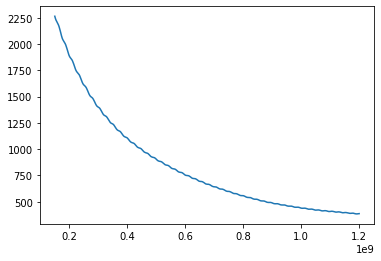

In [127]:
from matplotlib import pyplot as plt

plt.plot(freqs, np.abs(proc1.field))


In [128]:
abs_amp = np.max(np.abs(np.fft.ifft(proc1.field.T*np.hanning(500),1024)*np.linspace(1,1,1024)**2).T)

227.11549848484847
-116.96454772629747


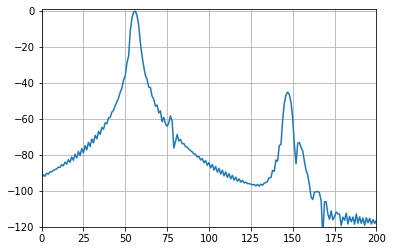

In [129]:
df = 660e6/500
print(299792458./df)
xx =np.linspace(0.,299792458./df,1024)
plt.plot( 20*np.log10(np.abs(np.fft.ifft(proc1.field.T*np.hanning(500),1024)*np.linspace(1,1,1024)**2).T/abs_amp))

print(np.max(20*np.log10(np.abs(np.fft.ifft(proc1.field.T*np.hanning(500),1024)*np.linspace(1,1,1024)**2).T/abs_amp)[250:300]))

plt.ylim(-120, 1)
plt.xlim(0,200)
plt.grid()

(0.0, 600.0)

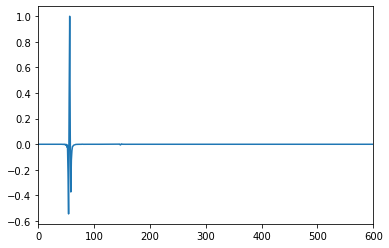

In [130]:
abs_amp = np.max(np.abs(np.real(np.fft.ifft(proc1.field.T*np.hanning(500),1024)*np.linspace(1,1,1024)**2).T))
plt.plot(np.real(np.fft.ifft(proc1.field.T*np.hanning(500),1024)*np.linspace(1,1,1024)**2).T/abs_amp)
plt.xlim(0,600)

In [131]:
np.save(f'{save_dir}/single_pos_raw_{model_prefix}_cosine_pattern_{model}.npy', proc1.field)

# Radargram

In [89]:
n_samples = 51

radargram = np.zeros((500, n_samples), dtype=np.complex)

freqs = np.linspace(120e6, 1200e6, 500)

model = "SRC_RES_6_SPP_10"
model_prefix = 'rimfax'
save_dir = f'models/{model_prefix}'
sim_dir = f'{save_dir}/{model}' 

In [90]:
from tqdm.notebook import tqdm

for i in tqdm(range(0,n_samples), desc='overall progress'):
    #print(f'Position {i}: ', flush=True)
    aggregator = FieldIntegrator(freqs)
    read_and_process_binary_emrt_raypaths(f'/home/garten/Projekte/Programmierung/rimfax/em_tracer/{sim_dir}/sweep_{i}_results.raypaths', aggregator, True)
    
    radargram[:, i] = aggregator.field

overall progress:   0%|          | 0/51 [00:00<?, ?it/s]

  0%|          | 0/199922 [00:00<?, ?it/s]

  0%|          | 0/200077 [00:00<?, ?it/s]

  0%|          | 0/200349 [00:00<?, ?it/s]

  0%|          | 0/200656 [00:00<?, ?it/s]

...

  0%|          | 0/200768 [00:00<?, ?it/s]

  0%|          | 0/200591 [00:00<?, ?it/s]

  0%|          | 0/200346 [00:00<?, ?it/s]

  0%|          | 0/200302 [00:00<?, ?it/s]

  0%|          | 0/200129 [00:00<?, ?it/s]

In [91]:
from matplotlib import pyplot as plt

In [92]:
abs_amp = np.max(np.abs(np.real(np.fft.ifft(radargram.T*np.hanning(500),1024,axis=1)*np.linspace(1,1,1024)**2).T))
print(abs_amp)

379.42471203978187


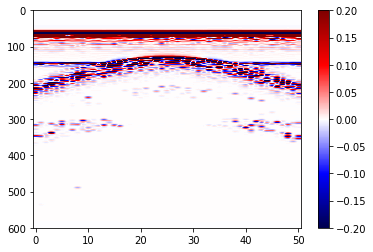

In [93]:
plt.imshow(np.real((np.fft.ifft(radargram.T*np.hanning(500),1024,axis=1)*np.linspace(1,100,1024)**2).T)/abs_amp,origin='upper',aspect='auto',cmap='seismic',vmin=-0.2,vmax=0.2)
#plt.imshow(np.real(np.fft.ifft(x.T*np.hanning(500),2048,axis=1).T),origin='upper',aspect='auto',vmin=-0.01,vmax=0.01)
plt.ylim(600, 0)
#plt.xlim(75, 125)
plt.colorbar()

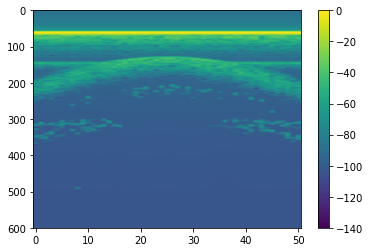

In [94]:
plt.imshow(20*np.log10(np.abs((np.fft.ifft(radargram.T*np.kaiser(500,9),1024,axis=1)*np.linspace(1,1,1024)**2).T)/abs_amp), origin='upper',aspect='auto', vmin=-140, vmax=0)
#plt.imshow(np.real(np.fft.ifft(x.T*np.hanning(500),2048,axis=1).T),origin='upper',aspect='auto',vmin=-0.01,vmax=0.01)
plt.ylim((600, 0))
#plt.xlim(0, 50)
plt.colorbar()

In [95]:
np.save(f'{save_dir}/radargram_raw_{model_prefix}_cosine_pattern_{model}_neu.npy', radargram)

In [ ]:
x = np.load("radargram_raw_plane_cosine_pattern.npy")

In [ ]:
print(np.min(np.real((np.fft.ifft(x.T*np.hanning(500),1024,axis=1)*np.linspace(1,1,1024)**2).T)))

In [ ]:
plt.imshow(np.real((np.fft.ifft(x.T*np.hanning(500),1024,axis=1)*np.linspace(1,1,1024)**2).T),origin='upper',aspect='auto',cmap='seismic',vmin=-0.1,vmax=0.1)
#plt.imshow(np.real(np.fft.ifft(x.T*np.hanning(500),2048,axis=1).T),origin='upper',aspect='auto',vmin=-0.01,vmax=0.01)
plt.ylim((200,0))
plt.colorbar()